In [1]:
#cell 1
import torch
import numpy as np
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not detected. Check Kaggle Accelerator settings.")

print("NumPy:", np.__version__)

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
NumPy: 2.1.3


In [2]:
#cell 2
import os
import subprocess

REPO_URL = "https://github.com/arcprize/ARC-AGI-2.git"

PROJECT_DIR = "/kaggle/working/GridMind"
DATA_DIR = os.path.join(PROJECT_DIR, "data")

os.makedirs(PROJECT_DIR, exist_ok=True)

if not os.path.exists(os.path.join(PROJECT_DIR, ".git")):

    subprocess.run(
        [
            "git", "clone",
            "--depth", "1",
            REPO_URL,
            PROJECT_DIR
        ],
        check=True
    )

print("Dataset repository downloaded!")
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

Cloning into '/kaggle/working/GridMind'...


Dataset repository downloaded!
Project directory: /kaggle/working/GridMind
Data directory: /kaggle/working/GridMind/data


In [3]:
#cell 3
import os

TRAIN_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "training"
)

EVAL_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "evaluation"
)

print("Training directory exists:", os.path.exists(TRAIN_DIR))
print("Evaluation directory exists:", os.path.exists(EVAL_DIR))

train_files = [
    f for f in os.listdir(TRAIN_DIR)
    if f.endswith(".json")
]

eval_files = [
    f for f in os.listdir(EVAL_DIR)
    if f.endswith(".json")
]

print("Training tasks:", len(train_files))
print("Evaluation tasks:", len(eval_files))

Training directory exists: True
Evaluation directory exists: True
Training tasks: 1000
Evaluation tasks: 120


In [4]:
#cell 4
folders = [
    "src",
    "checkpoints",
    "experiments",
    "outputs",
    "outputs/visualizations",
    "outputs/predictions"
]

for folder in folders:

    path = os.path.join(PROJECT_DIR, folder)

    os.makedirs(path, exist_ok=True)

print("GridMind project folders created!")

for folder in folders:
    print("✓", folder)

GridMind project folders created!
✓ src
✓ checkpoints
✓ experiments
✓ outputs
✓ outputs/visualizations
✓ outputs/predictions


In [5]:
#cell 5
import json

first_task_file = sorted(train_files)[0]

first_task_path = os.path.join(
    TRAIN_DIR,
    first_task_file
)

with open(first_task_path, "r") as f:
    task = json.load(f)

print("Task ID:", first_task_file.replace(".json", ""))

print("Number of training examples:", len(task["train"]))
print("Number of test examples:", len(task["test"]))

print("\nFirst training input:")
print(np.array(task["train"][0]["input"]))

print("\nFirst training output:")
print(np.array(task["train"][0]["output"]))

print("\nTest input:")
print(np.array(task["test"][0]["input"]))

Task ID: 00576224
Number of training examples: 2
Number of test examples: 1

First training input:
[[7 9]
 [4 3]]

First training output:
[[7 9 7 9 7 9]
 [4 3 4 3 4 3]
 [9 7 9 7 9 7]
 [3 4 3 4 3 4]
 [7 9 7 9 7 9]
 [4 3 4 3 4 3]]

Test input:
[[3 2]
 [7 8]]


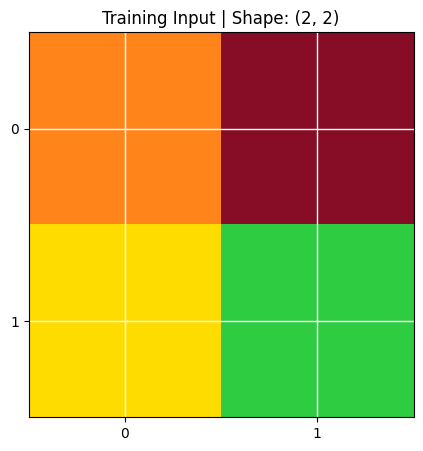

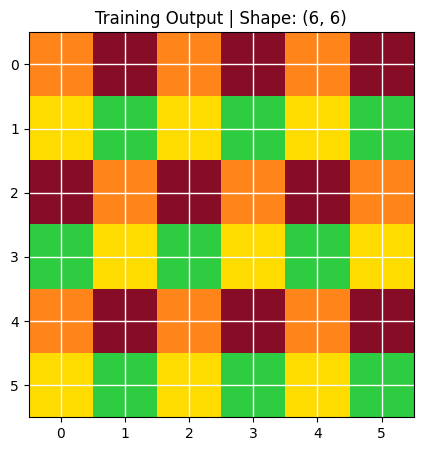

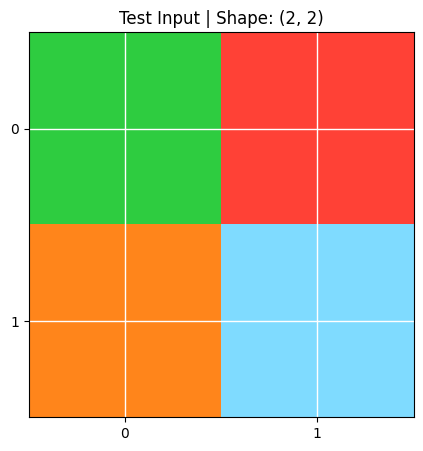

In [6]:
#cell 7
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ARC_COLORS = [
    "#000000",  # 0 - Black
    "#0074D9",  # 1 - Blue
    "#FF4136",  # 2 - Red
    "#2ECC40",  # 3 - Green
    "#FFDC00",  # 4 - Yellow
    "#AAAAAA",  # 5 - Grey
    "#F012BE",  # 6 - Magenta
    "#FF851B",  # 7 - Orange
    "#7FDBFF",  # 8 - Cyan
    "#870C25"   # 9 - Maroon
]

cmap = ListedColormap(ARC_COLORS)


def show_grid(grid, title="ARC Grid"):

    grid = np.array(grid)

    plt.figure(figsize=(5, 5))

    plt.imshow(
        grid,
        cmap=cmap,
        vmin=0,
        vmax=9
    )

    plt.title(
        f"{title} | Shape: {grid.shape}"
    )

    plt.xticks(range(grid.shape[1]))
    plt.yticks(range(grid.shape[0]))

    plt.grid(
        color="white",
        linewidth=1
    )

    plt.show()


show_grid(
    task["train"][0]["input"],
    "Training Input"
)

show_grid(
    task["train"][0]["output"],
    "Training Output"
)

show_grid(
    task["test"][0]["input"],
    "Test Input"
)

In [7]:
#cell 8
from collections import Counter

stats = {
    "total_tasks": 0,
    "total_train_pairs": 0,
    "total_test_pairs": 0,
    "grid_shapes": [],
    "colors": Counter(),
    "train_examples_per_task": []
}

for filename in train_files:

    path = os.path.join(TRAIN_DIR, filename)

    with open(path, "r") as f:
        data = json.load(f)

    stats["total_tasks"] += 1

    stats["total_train_pairs"] += len(data["train"])
    stats["total_test_pairs"] += len(data["test"])

    stats["train_examples_per_task"].append(
        len(data["train"])
    )

    for pair in data["train"]:

        for key in ["input", "output"]:

            grid = np.array(pair[key])

            stats["grid_shapes"].append(grid.shape)

            unique, counts = np.unique(
                grid,
                return_counts=True
            )

            for color, count in zip(unique, counts):

                stats["colors"][int(color)] += int(count)


print("Total Tasks:", stats["total_tasks"])

print("Training Pairs:", stats["total_train_pairs"])

print("Test Pairs:", stats["total_test_pairs"])

print(
    "Average training examples:",
    np.mean(stats["train_examples_per_task"])
)

print(
    "Minimum grid dimension:",
    min(min(s) for s in stats["grid_shapes"])
)

print(
    "Maximum grid dimension:",
    max(max(s) for s in stats["grid_shapes"])
)

print("\nColor frequency:")

for color, count in sorted(stats["colors"].items()):

    print(f"Color {color}: {count}")

Total Tasks: 1000
Training Pairs: 3232
Test Pairs: 1076
Average training examples: 3.232
Minimum grid dimension: 1
Maximum grid dimension: 30

Color frequency:
Color 0: 509919
Color 1: 78058
Color 2: 64134
Color 3: 58612
Color 4: 48896
Color 5: 37383
Color 6: 23560
Color 7: 62668
Color 8: 99251
Color 9: 12113


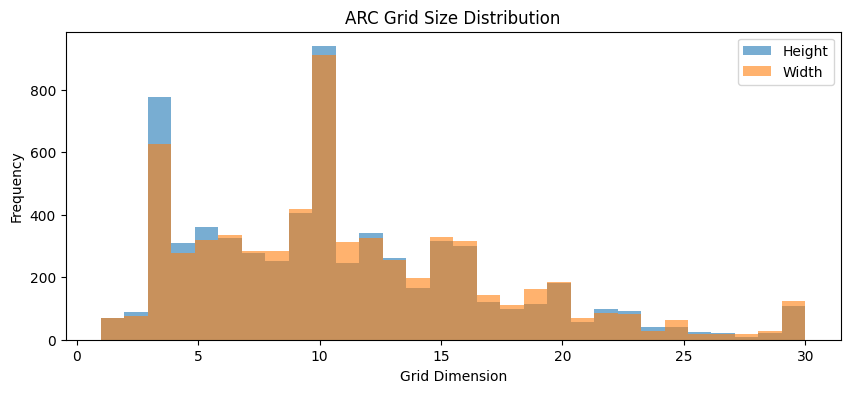

In [8]:
#cell 9
heights = [s[0] for s in stats["grid_shapes"]]
widths = [s[1] for s in stats["grid_shapes"]]

plt.figure(figsize=(10, 4))

plt.hist(
    heights,
    bins=30,
    alpha=0.6,
    label="Height"
)

plt.hist(
    widths,
    bins=30,
    alpha=0.6,
    label="Width"
)

plt.xlabel("Grid Dimension")
plt.ylabel("Frequency")
plt.title("ARC Grid Size Distribution")

plt.legend()
plt.show()

In [9]:
#cell 10
from sklearn.model_selection import train_test_split

task_ids = sorted([
    f.replace(".json", "")
    for f in train_files
])

train_ids, val_ids = train_test_split(
    task_ids,
    test_size=0.20,
    random_state=42
)

print("Training tasks:", len(train_ids))
print("Validation tasks:", len(val_ids))

# Save split
split_path = os.path.join(
    PROJECT_DIR,
    "experiments",
    "task_split.json"
)

with open(split_path, "w") as f:

    json.dump(
        {
            "train_ids": sorted(train_ids),
            "val_ids": sorted(val_ids),
            "random_seed": 42
        },
        f,
        indent=2
    )

print("Task split saved:", split_path)

Training tasks: 800
Validation tasks: 200
Task split saved: /kaggle/working/GridMind/experiments/task_split.json


In [10]:
#cell 11
import os
import json
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

GRID_SIZE = 30
NUM_CHANNELS = 11
NUM_COLORS = 10

def encode_grid(grid):
    grid = np.array(grid, dtype=np.int64)

    h, w = grid.shape

    encoded = np.zeros(
        (NUM_CHANNELS, GRID_SIZE, GRID_SIZE),
        dtype=np.float32
    )

    # One-hot colour encoding
    for color in range(NUM_COLORS):
        encoded[color, :h, :w] = (grid == color)

    # Valid-cell mask
    encoded[10, :h, :w] = 1.0

    return torch.tensor(encoded), h, w


def encode_target(grid):
    grid = np.array(grid, dtype=np.int64)

    h, w = grid.shape

    target = torch.full(
        (GRID_SIZE, GRID_SIZE),
        -100,
        dtype=torch.long
    )

    target[:h, :w] = torch.tensor(grid)

    return target, h, w

In [11]:
#cell 12
class GridMindDataset(Dataset):

    def __init__(self, task_ids, data_dir, seed=42):
        self.task_ids = list(task_ids)
        self.data_dir = data_dir
        self.seed = seed
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __len__(self):
        return len(self.task_ids)

    def __getitem__(self, idx):

        task_id = self.task_ids[idx]
        file_path = os.path.join(
            self.data_dir,
            task_id + ".json"
        )

        with open(file_path, "r") as f:
            task = json.load(f)

        examples = task["train"]

        # Deterministic but different query across epochs
        rng = random.Random(
            self.seed + self.epoch * 100003 + idx
        )

        query_idx = rng.randrange(len(examples))

        query_example = examples[query_idx]

        support_examples = [
            example
            for i, example in enumerate(examples)
            if i != query_idx
        ]

        support_inputs = []
        support_outputs = []

        for example in support_examples:

            x, _, _ = encode_grid(example["input"])
            y, _, _ = encode_grid(example["output"])

            support_inputs.append(x)
            support_outputs.append(y)

        query_input, qh, qw = encode_grid(
            query_example["input"]
        )

        query_target, th, tw = encode_target(
            query_example["output"]
        )

        return {
            "support_inputs": torch.stack(support_inputs),
            "support_outputs": torch.stack(support_outputs),
            "query_input": query_input,
            "query_target": query_target,
            "query_size": torch.tensor([qh, qw]),
            "target_size": torch.tensor([th, tw]),
            "task_id": task_id
        }

In [12]:
#cell 13
def gridmind_collate(batch):

    batch_size = len(batch)
    max_support = max(
        item["support_inputs"].shape[0]
        for item in batch
    )

    support_inputs = torch.zeros(
        batch_size, max_support,
        NUM_CHANNELS, GRID_SIZE, GRID_SIZE
    )

    support_outputs = torch.zeros_like(support_inputs)

    support_mask = torch.zeros(
        batch_size, max_support,
        dtype=torch.bool
    )

    for i, item in enumerate(batch):

        n = item["support_inputs"].shape[0]

        support_inputs[i, :n] = item["support_inputs"]
        support_outputs[i, :n] = item["support_outputs"]

        support_mask[i, :n] = True

    return {
        "support_inputs": support_inputs,
        "support_outputs": support_outputs,
        "support_mask": support_mask,

        "query_input": torch.stack([
            item["query_input"] for item in batch
        ]),

        "query_target": torch.stack([
            item["query_target"] for item in batch
        ]),

        "query_size": torch.stack([
            item["query_size"] for item in batch
        ]),

        "target_size": torch.stack([
            item["target_size"] for item in batch
        ]),

        "task_id": [
            item["task_id"] for item in batch
        ]
    }

In [13]:
#cell 14
train_dataset = GridMindDataset(
    train_ids,
    TRAIN_DIR,
    seed=42
)

val_dataset = GridMindDataset(
    val_ids,
    TRAIN_DIR,
    seed=1000
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=gridmind_collate,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=gridmind_collate,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 100
Validation batches: 25


In [14]:
#cell 15
batch = next(iter(train_loader))

for key, value in batch.items():

    if torch.is_tensor(value):
        print(key, value.shape, value.dtype)

    elif isinstance(value, list):
        print(key, value[:3])

support_inputs torch.Size([8, 2, 11, 30, 30]) torch.float32
support_outputs torch.Size([8, 2, 11, 30, 30]) torch.float32
support_mask torch.Size([8, 2]) torch.bool
query_input torch.Size([8, 11, 30, 30]) torch.float32
query_target torch.Size([8, 30, 30]) torch.int64
query_size torch.Size([8, 2]) torch.int64
target_size torch.Size([8, 2]) torch.int64
task_id ['e26a3af2', '7e576d6e', 'bf32578f']
